In [7]:
import numpy as np
import matplotlib.pyplot as plt
import time
import cv2

In [8]:
# Sử dụng hàm convolve2d của Gấm
def convolve2d(image, kernel, padding="constant"):
    image = np.asarray(image, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)

    if image.ndim != 2 or kernel.ndim != 2:
        raise ValueError("Image và kernel phải là mảng 2 chiều")

    kh, kw = kernel.shape

    if kh % 2 == 0 or kw % 2 == 0:
        raise ValueError("Kernel phải có kích thước lẻ")

    if padding not in ("constant", "reflect", "edge"):
        raise ValueError("Padding không hợp lệ")

    ph, pw = kh // 2, kw // 2

    padded = np.pad(
        image,
        ((ph, ph), (pw, pw)),
        mode=padding
    )

    flipped = np.flip(kernel, axis=(0, 1))

    h, w = image.shape
    output = np.zeros((h, w), dtype=np.float64)

    for i in range(h):
        for j in range(w):
            region = padded[i:i+kh, j:j+kw]
            output[i, j] = np.sum(region * flipped)

    return output

## Tấn Lên – Demo 3b: Phát hiện biên Sobel và Làm sắc nét ảnh

**Mục tiêu:**
- Áp dụng các kernel Sobel X và Sobel Y để tính toán gradient của ảnh.
- Tính toán độ lớn và hướng của gradient.
- Áp dụng toán tử Laplacian để làm sắc nét ảnh.
- Trực quan hóa và phân tích kết quả xử lý.

Các thí nghiệm sử dụng hàm `convolve2d` của nhóm để thực hiện phép chập với các kernel khác nhau.

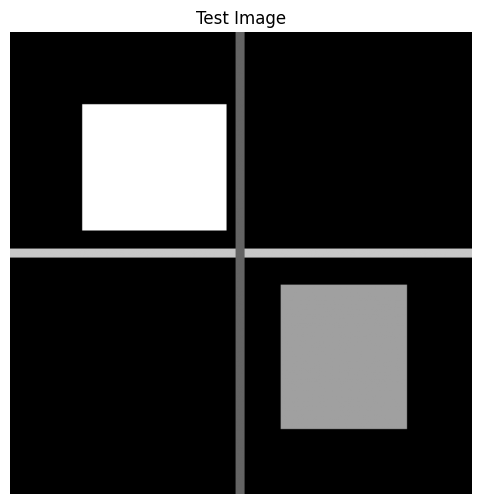

In [9]:
#  Tạo ảnh thử nghiệm 
height, width = 256, 256
img_demo = np.zeros((height, width), dtype=np.uint8)

# Add bright and gray rectangles
img_demo[40:110, 40:120] = 255
img_demo[140:220, 150:220] = 160

# Add horizontal and vertical structures
img_demo[120:125, :] = 200
img_demo[:, 125:130] = 100

# Display the test image
plt.figure(figsize=(6, 6))
plt.imshow(img_demo, cmap="gray", vmin=0, vmax=255)
plt.title("Test Image")
plt.axis("off")
plt.show()

In [10]:
 
# Sobel edge detection

img_float = img_demo.astype(np.float64)

sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float64)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float64)

# convolve2d thực hiện tích chập thật nên cần lật kernel
sobel_x_conv = np.flip(sobel_x, axis=(0, 1))
sobel_y_conv = np.flip(sobel_y, axis=(0, 1))

gx = convolve2d(
    img_float, sobel_x_conv, padding="reflect"
)

gy = convolve2d(
    img_float, sobel_y_conv, padding="reflect"
)

edge_magnitude = np.sqrt(gx**2 + gy**2)

edge_direction = np.degrees(
    np.arctan2(gy, gx)
)

print("Sobel completed!")
print("gx:", gx.shape)
print("gy:", gy.shape)
 

Sobel completed!
gx: (256, 256)
gy: (256, 256)


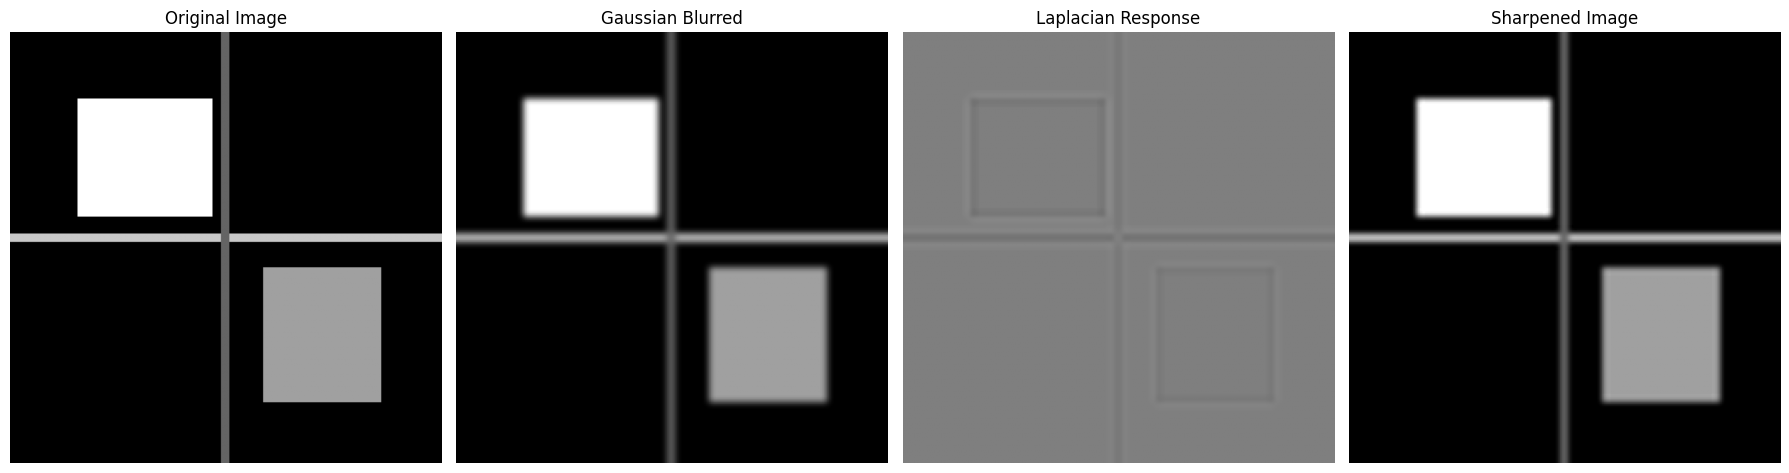

In [11]:
# Convert original image to float64
img_float = img_demo.astype(np.float64)

# Blur the image first to make the sharpening effect more visible
img_blurred = cv2.GaussianBlur(
    img_float,
    ksize=(9, 9),
    sigmaX=2.0,
    sigmaY=2.0,
    borderType=cv2.BORDER_REFLECT101
)

# 4-neighbor Laplacian kernel
laplacian_kernel = np.array([
    [ 0,  1,  0],
    [ 1, -4,  1],
    [ 0,  1,  0]
], dtype=np.float64)

# Apply Laplacian to the blurred image
laplacian = convolve2d(
    img_blurred,
    laplacian_kernel,
    padding="reflect"
)

# Sharpen the blurred image
alpha = 1.0
sharpened_float = img_blurred - alpha * laplacian

# Clip to valid image range
sharpened = np.clip(
    np.round(sharpened_float), 0, 255
).astype(np.uint8)

# Convert for display
img_blurred_display = np.clip(
    np.round(img_blurred), 0, 255
).astype(np.uint8)

laplacian_display = np.clip(
    127.5 + laplacian / 2, 0, 255
).astype(np.uint8)

# Compare original, blurred, Laplacian and sharpened images
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img_demo, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")

axes[1].imshow(
    img_blurred_display, cmap="gray", vmin=0, vmax=255
)
axes[1].set_title("Gaussian Blurred")

axes[2].imshow(
    laplacian_display, cmap="gray", vmin=0, vmax=255
)
axes[2].set_title("Laplacian Response")

axes[3].imshow(sharpened, cmap="gray", vmin=0, vmax=255)
axes[3].set_title("Sharpened Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

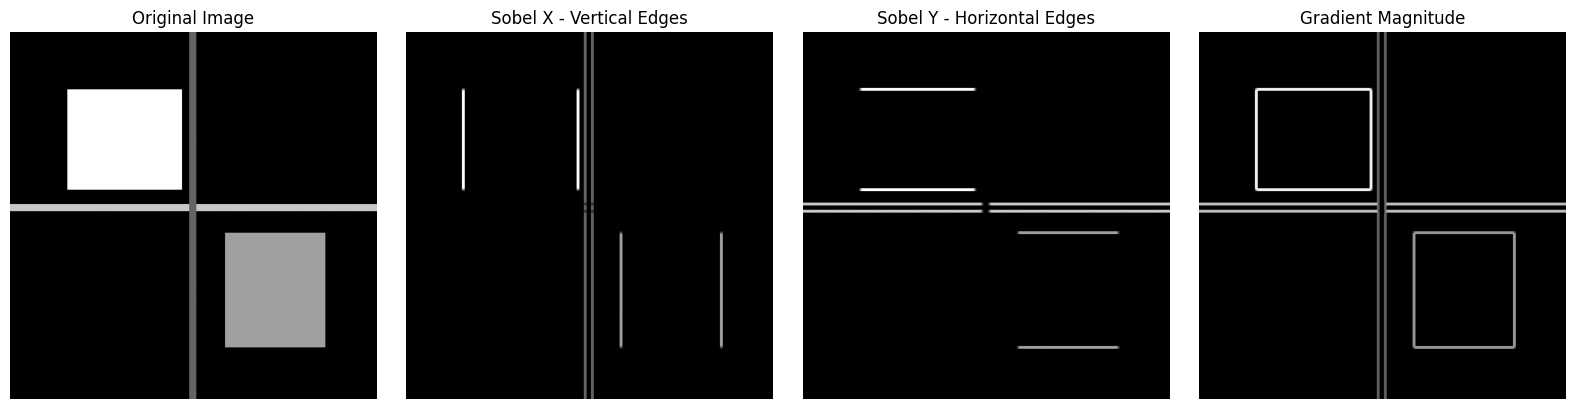

In [12]:
 
# Visualize Sobel edge detection

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

axes[0].imshow(img_demo, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(np.abs(gx), cmap="gray")
axes[1].set_title("Sobel X - Vertical Edges")

axes[2].imshow(np.abs(gy), cmap="gray")
axes[2].set_title("Sobel Y - Horizontal Edges")

axes[3].imshow(edge_magnitude, cmap="gray")
axes[3].set_title("Gradient Magnitude")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

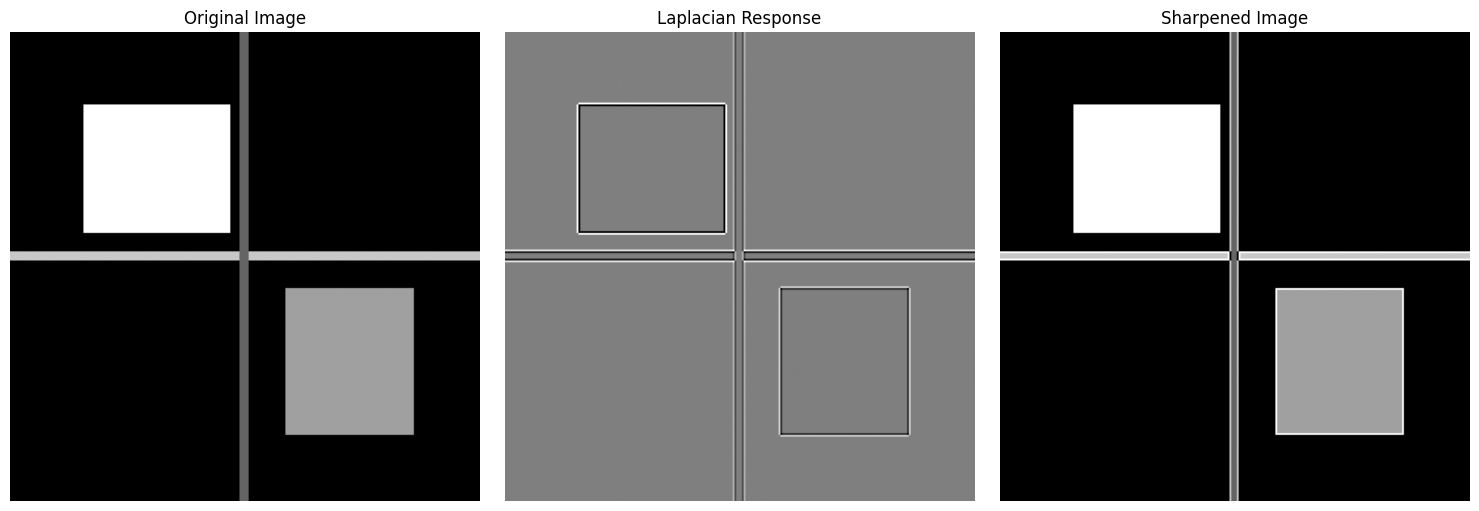

In [13]:
# Làm sắc nét bằng Laplacian
laplacian_kernel = np.array([
    [ 0,  1,  0],
    [ 1, -4,  1],
    [ 0,  1,  0]
], dtype=np.float64)

# Apply Laplacian convolution
laplacian = convolve2d(
    img_float,
    laplacian_kernel,
    padding="reflect"
)

# Sharpen the image
alpha = 1.0
sharpened_float = img_float - alpha * laplacian

# Clip pixel values to the valid range
sharpened = np.clip(
    np.round(sharpened_float),
    0,
    255
).astype(np.uint8)

# Normalize Laplacian for visualization only
laplacian_display = np.clip(
    127.5 + laplacian / 2,
    0,
    255
).astype(np.uint8)

# Compare the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(img_demo, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("Original Image")

axes[1].imshow(
    laplacian_display,
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[1].set_title("Laplacian Response")

axes[2].imshow(
    sharpened,
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[2].set_title("Sharpened Image")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
# Kiểm tra kích thước, kiểu dữ liệu và kết quả

# 1. Kiểm tra các biến đầu vào đã tồn tại chưa
required_vars = [
    "img_demo",
    "gx",
    "gy",
    "edge_magnitude",
    "edge_direction",
    "laplacian",
    "sharpened"
]

missing_vars = [
    name for name in required_vars
    if name not in globals()
]

if missing_vars:
    print("ERROR: Các biến chưa được tạo:", missing_vars)
    print("Hãy chạy lại các cell tạo ảnh, Sobel và Laplacian ở phía trên.")
else:
    # 2. In kích thước và kiểu dữ liệu
    print("Original image:", img_demo.shape, img_demo.dtype)
    print("Sobel X:", gx.shape, gx.dtype)
    print("Sobel Y:", gy.shape, gy.dtype)
    print("Gradient magnitude:", edge_magnitude.shape,
          edge_magnitude.dtype)
    print("Gradient direction:", edge_direction.shape,
          edge_direction.dtype)
    print("Laplacian:", laplacian.shape, laplacian.dtype)
    print("Sharpened image:", sharpened.shape, sharpened.dtype)

    # 3. Thống kê gradient
    print("\nMaximum gradient magnitude:",
          float(np.max(edge_magnitude)))

    print("Number of pixels with nonzero gradient:",
          int(np.count_nonzero(edge_magnitude)))

    # 4. Kiểm tra các đầu ra có cùng kích thước không
    all_shapes_match = (
        img_demo.shape == gx.shape
        == gy.shape
        == edge_magnitude.shape
        == edge_direction.shape
        == laplacian.shape
        == sharpened.shape
    )

    print("All output shapes match:", all_shapes_match)

    # 5. Kiểm tra giá trị không hợp lệ
    arrays_to_check = {
        "gx": gx,
        "gy": gy,
        "edge_magnitude": edge_magnitude,
        "edge_direction": edge_direction,
        "laplacian": laplacian,
        "sharpened": sharpened
    }

    for name, array in arrays_to_check.items():
        print(
            f"{name} contains NaN/Inf:",
            bool(np.any(~np.isfinite(array)))
        )


Original image: (256, 256) uint8
Sobel X: (256, 256) float64
Sobel Y: (256, 256) float64
Gradient magnitude: (256, 256) float64
Gradient direction: (256, 256) float64
Laplacian: (256, 256) float64
Sharpened image: (256, 256) uint8

Maximum gradient magnitude: 1081.8733752154178
Number of pixels with nonzero gradient: 3220
All output shapes match: True
gx contains NaN/Inf: False
gy contains NaN/Inf: False
edge_magnitude contains NaN/Inf: False
edge_direction contains NaN/Inf: False
laplacian contains NaN/Inf: False
sharpened contains NaN/Inf: False


*** Vòng 2 – KT3: Hough Transform 

In [15]:
# hàm hough_accumulate

import numpy as np


def hough_accumulate(
    edge_map,
    theta_resolution=np.pi / 180,
    rho_resolution=1.0,
    gradient_direction=None,
    gradient_tolerance=np.deg2rad(15)
):
    """
    Tạo bảng phiếu Hough cho đường thẳng.

    Parameters
    ----------
    edge_map : 2D array
        Điểm cạnh có giá trị khác 0 được dùng để bỏ phiếu.
    theta_resolution : float
        Bước góc, tính bằng radian.
    rho_resolution : float
        Bước lượng tử hóa rho, tính bằng pixel.
    gradient_direction : 2D array or None
        Hướng gradient tại mỗi pixel, tính bằng radian.
        Nếu None, mỗi điểm cạnh bỏ phiếu cho mọi theta.
    gradient_tolerance : float
        Sai số góc cho phép khi dùng hướng gradient, tính bằng radian.

    Returns
    -------
    accumulator : 2D array
        Bảng phiếu có trục thứ nhất là rho, trục thứ hai là theta.
    rhos : 1D array
        Các giá trị rho tương ứng với từng hàng.
    thetas : 1D array
        Các giá trị theta tương ứng với từng cột.
    """
    edge_map = np.asarray(edge_map)

    if edge_map.ndim != 2:
        raise ValueError("edge_map phải là ảnh 2 chiều.")

    if theta_resolution <= 0 or rho_resolution <= 0:
        raise ValueError("Các bước lượng tử hóa phải dương.")

    if gradient_tolerance < 0:
        raise ValueError("gradient_tolerance không được âm.")

    height, width = edge_map.shape

    if gradient_direction is not None:
        gradient_direction = np.asarray(gradient_direction)

        if gradient_direction.shape != edge_map.shape:
            raise ValueError(
                "gradient_direction phải có cùng kích thước edge_map."
            )

    # Tọa độ các pixel cạnh
    ys, xs = np.nonzero(edge_map)

    # Phạm vi rho đủ bao phủ ảnh
    diagonal = np.hypot(height - 1, width - 1)
    rhos = np.arange(
        -diagonal,
        diagonal + rho_resolution,
        rho_resolution
    )

    # Dùng khoảng theta [-pi/2, pi/2)
    thetas = np.arange(
        -np.pi / 2,
        np.pi / 2,
        theta_resolution
    )

    accumulator = np.zeros(
        (len(rhos), len(thetas)),
        dtype=np.int64
    )

    cos_t = np.cos(thetas)
    sin_t = np.sin(thetas)

    for x, y in zip(xs, ys):
        # rho(theta) của điểm cạnh hiện tại
        rho_values = x * cos_t + y * sin_t

        # Mặc định: bỏ phiếu cho mọi góc theta
        valid = np.ones(len(thetas), dtype=bool)

        if gradient_direction is not None:
            grad_angle = gradient_direction[y, x]

            # Hướng pháp tuyến của đường thẳng tương đương modulo pi
            angle_diff = (
                (thetas - grad_angle + np.pi / 2) % np.pi
            ) - np.pi / 2

            valid = np.abs(angle_diff) <= gradient_tolerance

        rho_indices = np.rint(
            (rho_values[valid] - rhos[0]) / rho_resolution
        ).astype(int)

        theta_indices = np.flatnonzero(valid)

        # Bỏ phiếu cho các ô (rho, theta) hợp lệ
        np.add.at(
            accumulator,
            (rho_indices, theta_indices),
            1
        )

    return accumulator, rhos, thetas


In [16]:
# hàm find_peaks
def find_peaks(
    accumulator,
    rhos,
    thetas,
    num_peaks=10,
    threshold=0.0,
    smooth=True,
    min_distance_rho=5,
    min_distance_theta=5
):
    """
    Làm mượt bảng phiếu Hough bằng convolve2d và tìm các đỉnh.

    Returns
    -------
    peaks : list of tuples
        Mỗi phần tử là (rho, theta, vote_count).
        theta tính bằng radian.
    smoothed : 2D array
        Bảng phiếu sau khi làm mượt.
    """
    accumulator = np.asarray(accumulator, dtype=np.float64)
    rhos = np.asarray(rhos)
    thetas = np.asarray(thetas)

    if accumulator.ndim != 2:
        raise ValueError("accumulator phải là mảng 2 chiều.")

    if accumulator.shape != (len(rhos), len(thetas)):
        raise ValueError("Kích thước accumulator không khớp rhos/thetas.")

    if num_peaks < 0:
        raise ValueError("num_peaks không được âm.")

    if min_distance_rho < 0 or min_distance_theta < 0:
        raise ValueError("Khoảng cách tối thiểu không được âm.")

    if smooth:
        # Kernel trung bình 3x3; tổng trọng số bằng 1
        smoothing_kernel = np.ones((3, 3), dtype=np.float64) / 9.0

        # Dùng hàm tích chập chung của nhóm
        smoothed = convolve2d(
            accumulator,
            smoothing_kernel,
            padding="reflect"
        )
    else:
        smoothed = accumulator.copy()

    peaks = []
    working = smoothed.copy()

    for _ in range(num_peaks):
        flat_index = np.argmax(working)
        rho_idx, theta_idx = np.unravel_index(
            flat_index, working.shape
        )
        peak_value = working[rho_idx, theta_idx]

        if peak_value <= threshold:
            break

        peaks.append((
            float(rhos[rho_idx]),
            float(thetas[theta_idx]),
            float(smoothed[rho_idx, theta_idx])
        ))

        # Loại các đỉnh quá gần đỉnh vừa lấy
        r0 = max(0, rho_idx - min_distance_rho)
        r1 = min(working.shape[0], rho_idx + min_distance_rho + 1)
        t0 = max(0, theta_idx - min_distance_theta)
        t1 = min(working.shape[1], theta_idx + min_distance_theta + 1)

        working[r0:r1, t0:t1] = -np.inf

    return peaks, smoothed


In [17]:
print("convolve2d exists:", "convolve2d" in globals())

if "convolve2d" in globals():
    print(convolve2d)

convolve2d exists: True
<function convolve2d at 0x00000224C8E26340>


In [18]:

# Tạo ảnh thử có một đường thẳng đứng
test_edges = np.zeros((160, 160), dtype=np.uint8)
test_edges[20:140, 80] = 1

# 1. Bỏ phiếu không sử dụng hướng gradient
accumulator, rhos, thetas = hough_accumulate(test_edges)
peaks, smoothed = find_peaks(
    accumulator,
    rhos,
    thetas,
    num_peaks=5,
    threshold=0,
    smooth=True,
    min_distance_rho=5,
    min_distance_theta=5
)

print("Top Hough peaks (rho, theta in radians, votes):")
for peak in peaks:
    print(peak)

# Kiểm tra đỉnh gần nghiệm dự kiến nhất
if peaks:
    rho_found, theta_found, votes = peaks[0]
    print("\nExpected rho:", 80)
    print("Expected theta:", 0)
    print("Found rho:", rho_found)
    print("Found theta:", theta_found)

    assert abs(rho_found - 80) <= 2, "rho chưa đúng!"
    assert abs(theta_found) <= np.deg2rad(2), "theta chưa đúng!"

    print("PASS: Hough peak is close to (rho0, theta0).")


Top Hough peaks (rho, theta in radians, votes):
(81.14004358267789, 0.01745329251994554, 33.11111111111111)
(75.14004358267789, -0.05235987755982774, 16.11111111111111)
(87.14004358267789, 0.0698131700797755, 11.888888888888888)
(69.14004358267789, -0.1047197551196577, 9.88888888888889)
(93.14004358267789, 0.12217304763960546, 7.777777777777778)

Expected rho: 80
Expected theta: 0
Found rho: 81.14004358267789
Found theta: 0.01745329251994554
PASS: Hough peak is close to (rho0, theta0).


In [21]:

# Hướng gradient của đường cạnh thử
test_gradient_direction = np.zeros(
    test_edges.shape,
    dtype=np.float64
)

accumulator_grad, rhos_grad, thetas_grad = hough_accumulate(
    test_edges,
    gradient_direction=test_gradient_direction,
    gradient_tolerance=np.deg2rad(10)
)

peaks_grad, smoothed_grad = find_peaks(
    accumulator_grad,
    rhos_grad,
    thetas_grad,
    num_peaks=5,
    threshold=0,
    smooth=True
)

print("Top peaks with gradient voting:")
for peak in peaks_grad:
    print(peak)

assert len(peaks_grad) > 0, "Không tìm được đỉnh khi dùng gradient!"

rho_grad, theta_grad, _ = peaks_grad[0]

assert abs(rho_grad - 80) <= 2
assert abs(theta_grad) <= np.deg2rad(2)

print("PASS: Gradient-guided voting finds the expected line.")


Top peaks with gradient voting:
(81.14004358267789, 0.01745329251994554, 33.11111111111111)
(75.14004358267789, -0.05235987755982774, 16.11111111111111)
(87.14004358267789, 0.0698131700797755, 11.888888888888888)
(69.14004358267789, -0.1047197551196577, 9.88888888888889)
(93.14004358267789, 0.12217304763960546, 7.777777777777778)
PASS: Gradient-guided voting finds the expected line.
